<a href="https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01b_workflows_vs_agents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 1B: LLM call, workflow, agentic workflow, or agent?

**AgentForge Workshop · Tutorial 1, notebook B of 2 · about 25 minutes**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AgentForgeWorkshop/Tutorials/blob/main/Tutorial1_frameworks/01b_workflows_vs_agents.ipynb)

The slides asked one question of every system: **who decides the next step: you, your code,
or the LLM?** Here you build the same task four ways and measure the difference.

> **Task:** "Send me a digest of this week's new arXiv papers on my topic."

| Step | Level | Who decides | Built with | Min |
|---|---|---|---|---|
| 0 | Setup | | | 3 |
| 1 | LLM call | You | a chat model | 2 |
| 2 | LLM workflow | Your code | LangGraph | 5 |
| 3 | Agentic workflow | Your code, with the LLM inside one step | LangGraph | 6 |
| 4 | Agent | The LLM | LangChain | 5 |
| 5 | Compare the four | | pandas | 4 |

Notebook A showed what an agent is. Here, the agent is only one of four options, and often
not the best one.

---
## Step 0: Setup

Run the three cells below. The third one holds helpers from notebook A (`search_arxiv`,
`show_trace`, `draw`) plus a `track` helper that counts LLM calls, tokens and seconds for each
run. You do not need to read it.

In [3]:
%pip install -q "langchain==1.4.2" "langchain-google-genai==4.4.0" "langchain-openai==1.6.2"

In [4]:
import getpass
import os

from langchain.chat_models import init_chat_model


def get_key(name: str) -> str:
    """Read an API key from Colab's Secrets panel, or ask for it if there is none."""
    try:
        from google.colab import userdata

        return userdata.get(name)
    except Exception:  # not in Colab, or that secret is not set
        return os.environ.get(name) or getpass.getpass(f"{name}: ")


PROVIDER = "openrouter"  # <-- "openrouter" or "google"

if PROVIDER == "openrouter":
    MODEL_NAME = "openai:deepseek/deepseek-v4.1-flash"
    model = init_chat_model(
        MODEL_NAME,
        temperature=0,
        base_url="https://openrouter.ai/api/v1",
        api_key=get_key("OPENROUTER_API_KEY"),
    )
elif PROVIDER == "google":
    os.environ["GOOGLE_API_KEY"] = get_key("GOOGLE_API_KEY")
    MODEL_NAME = "google_genai:gemini-3.5-flash"
    model = init_chat_model(MODEL_NAME, temperature=0)

TOPIC = "machine learning interatomic potentials for catalysis"  # <-- change me
# Deliberately far too specific: an AND of all these words finds nothing on arXiv.
NARROW = "graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning"

print("Model ready:", MODEL_NAME)

Model ready: openai:deepseek/deepseek-v4.1-flash


In [5]:
# @title Helpers from notebook A, plus run tracking (just run this cell)
import re
import textwrap
import time
import urllib.parse
import urllib.request
import xml.etree.ElementTree as ET
from contextlib import contextmanager
from contextvars import ContextVar
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import HumanMessage
from langchain_core.tracers.context import register_configure_hook

ARXIV_API = "https://export.arxiv.org/api/query"
ATOM = {"atom": "http://www.w3.org/2005/Atom"}
STOPWORDS = {"a", "an", "and", "are", "as", "at", "based", "by", "for", "from", "in",
             "into", "is", "of", "on", "or", "the", "to", "use", "using", "via", "with"}


def build_arxiv_query(topic: str) -> str:
    """Translate a plain-English topic into arXiv's query language (AND of the words)."""
    words = re.findall(r"[A-Za-z0-9][\w'-]*", topic)
    terms = [w for w in words if w.lower() not in STOPWORDS]
    return " AND ".join(f"all:{w}" for w in terms) or f"all:{topic}"


def search_arxiv(query: str, max_results: int = 5) -> str:
    """Search arXiv for recent papers and return their titles, authors, links and abstracts.

    Args:
        query: Search terms, e.g. 'graph neural network catalyst screening'.
        max_results: How many papers to return (1-10).
    """
    search_query = build_arxiv_query(query)
    params = urllib.parse.urlencode({
        "search_query": search_query, "start": 0, "max_results": min(max_results, 10),
        "sortBy": "submittedDate", "sortOrder": "descending",
    })
    with urllib.request.urlopen(f"{ARXIV_API}?{params}", timeout=30) as response:
        feed = ET.fromstring(response.read())
    papers = []
    for entry in feed.findall("atom:entry", ATOM):
        title = " ".join(entry.findtext("atom:title", "", ATOM).split())
        abstract = " ".join(entry.findtext("atom:summary", "", ATOM).split())
        authors = [a.findtext("atom:name", "", ATOM) for a in entry.findall("atom:author", ATOM)]
        papers.append(
            f"Title: {title}\n"
            f"Authors: {', '.join(authors[:3])}{' et al.' if len(authors) > 3 else ''}\n"
            f"Published: {entry.findtext('atom:published', '', ATOM)[:10]}\n"
            f"Link: {entry.findtext('atom:id', '', ATOM)}\n"
            f"Abstract: {textwrap.shorten(abstract, 1000, placeholder=' ...')}"
        )
    if not papers:
        return (f"No papers found for '{query}' (sent to arXiv as: {search_query}). "
                "Try fewer or broader search terms.")
    return "\n\n---\n\n".join(papers)


def count_papers(result: str) -> int:
    return 0 if result.startswith("No papers found") else result.count("Title:")


def arxiv_ids(text: str) -> list:
    """All arXiv ids (like 2610.02013) mentioned in a text."""
    return sorted(set(re.findall(r"\b(\d{4}\.\d{4,5})(?:v\d+)?\b", text or "")))


def show_trace(result, width=200):
    """Print an agent run as Thought / Action / Observation."""
    for message in result["messages"]:
        kind = type(message).__name__
        text = (message.text or "").strip()
        if kind == "HumanMessage":
            print(f"You:         {textwrap.shorten(text, width)}")
        elif kind == "ToolMessage":
            found = count_papers(text) if text.startswith(("Title:", "No papers")) else None
            print(f"Observation: {f'{found} papers' if found is not None else textwrap.shorten(text, 100)}")
        elif message.tool_calls:
            if text:
                print(f"Thought:     {textwrap.shorten(text, width)}")
            for call in message.tool_calls:
                args = {k: textwrap.shorten(str(v), 60) for k, v in call["args"].items()}
                print(f"Action:      {call['name']}({args})")
        elif text:
            print(f"Answer:      {textwrap.shorten(text, width)}")


def draw(graph):
    """Draw a LangGraph graph (falls back to text if the drawing service is unreachable)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


class _Counter(BaseCallbackHandler):
    """Counts every LLM call made inside a `track` block, and the tokens it used."""

    def __init__(self):
        self.llm_calls, self.tokens = 0, 0

    def on_llm_end(self, response, **kwargs):
        self.llm_calls += 1
        for generation in response.generations:
            for g in generation:
                usage = getattr(getattr(g, "message", None), "usage_metadata", None) or {}
                self.tokens += usage.get("total_tokens", 0)


_counter = ContextVar("workshop_counter", default=None)
register_configure_hook(_counter, inheritable=True)
RUNS = []  # one row per tracked run, for the comparison in Step 5


@contextmanager
def track(level: str, topic: str):
    """Measure everything inside the `with` block: LLM calls, tokens, seconds."""
    counter, start = _Counter(), time.time()
    row = {"level": level, "topic": topic}
    token = _counter.set(counter)
    try:
        yield row
    finally:
        _counter.reset(token)
        row.update(llm_calls=counter.llm_calls, tokens=counter.tokens,
                   seconds=round(time.time() - start, 1))
        RUNS.append(row)
        calls = f"{counter.llm_calls} LLM call{'' if counter.llm_calls == 1 else 's'}"
        print(f"\n✓ {level} ({topic}): {calls}, {counter.tokens:,} tokens, "
              f"{row['seconds']} s")


print("Helpers ready.")

Helpers ready.


---
## Step 1: LLM call. **You** decide.

One prompt, one answer. We fetch one paper for you and ask for a summary.

In [6]:
one_paper = search_arxiv(TOPIC, max_results=1)

with track("1) LLM call", "normal topic") as run:
    reply = model.invoke(f"Summarise this paper for a colleague in 3 sentences, then give its link:\n\n{one_paper}")
    run["papers"] = arxiv_ids(reply.text)

print(reply.text)


✓ 1) LLM call (normal topic): 1 LLM call, 708 tokens, 2.3 s
BranchIP is a single-model framework that learns adaptive tensor-product computation for equivariant machine learning interatomic potentials, trained with a novel distillation loss. On a heterogeneous catalysis system and a proton-conducting solid acid electrolyte, it accelerates MLIPs by up to 2.4× and cuts memory use by up to 2.6× across model sizes while maintaining physical fidelity. Its learned adaptivity also aids interpretability by revealing which interactions require deeper computation.

Link: http://arxiv.org/abs/2610.02013v1


Good at what it does. But **you** chose the paper, **you** would repeat this for every
paper, and **you** would write and send the digest. Nothing here can search, retry, or act.

---
## Step 2: LLM workflow. **Your code** decides.

Now the steps are fixed in code: **search → summarise → write the digest → save**. Two of
those steps call the LLM, each working on the previous one's output: the *prompt chaining*
pattern from the slides.

We build it with **LangGraph**: each step is a Python function (a *node*) that reads a shared
`state` dict and returns the keys it changed. Edges say what runs next.

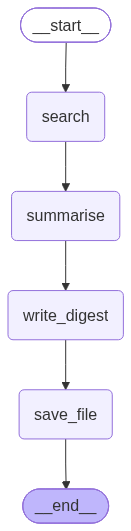

In [7]:
from typing import TypedDict

from langgraph.graph import END, START, StateGraph


class DigestState(TypedDict, total=False):
    topic: str      # what the scientist asked for
    query: str      # what we actually send to arXiv
    papers: str     # raw search results
    n_found: int
    attempts: int
    notes: str      # one bullet per paper
    digest: str     # the final email text


def search(state: DigestState) -> dict:                       # code, no LLM
    query = state.get("query") or state["topic"]
    papers = search_arxiv(query, max_results=5)
    print(f"  search({query!r}) -> {count_papers(papers)} papers")
    return {"query": query, "papers": papers, "n_found": count_papers(papers),
            "attempts": state.get("attempts", 0) + 1}


def summarise(state: DigestState) -> dict:                    # LLM
    notes = model.invoke(
        "For each paper below write one bullet: the title, the link, and the key finding "
        "in one sentence. Use only the text below.\n\n" + state["papers"]
    ).text
    return {"notes": notes}


def write_digest(state: DigestState) -> dict:                 # LLM
    digest = model.invoke(
        f"Turn these notes into a short weekly digest email for my lab about "
        f"'{state['topic']}'. Start with a subject line. Keep every link.\n\n{state['notes']}"
    ).text
    return {"digest": digest}


def save_file(state: DigestState) -> dict:                    # code, no LLM
    Path("digest.md").write_text(state["digest"], encoding="utf-8")
    return {}


builder = StateGraph(DigestState)
for step in (search, summarise, write_digest, save_file):
    builder.add_node(step)
builder.add_edge(START, "search")
builder.add_edge("search", "summarise")
builder.add_edge("summarise", "write_digest")
builder.add_edge("write_digest", "save_file")
builder.add_edge("save_file", END)

workflow = builder.compile()
draw(workflow)

In [8]:
with track("2) LLM workflow", "normal topic") as run:
    out = workflow.invoke({"topic": TOPIC})
    run["papers"] = arxiv_ids(out["digest"])

display(Markdown(out["digest"]))

  search('machine learning interatomic potentials for catalysis') -> 5 papers

✓ 2) LLM workflow (normal topic): 2 LLM calls, 5,575 tokens, 16.7 s


Subject: Weekly MLIP for Catalysis Digest — 5 new papers

Hi all,

Here’s this week’s MLIP-for-catalysis digest:

1. **BranchIP: Learning Adaptive Equivariant Computation for Interatomic Potentials** — http://arxiv.org/abs/2610.02013v1  
   BranchIP learns adaptive tensor product computation with a novel distillation loss, accelerating MLIPs up to 2.4× and reducing memory up to 2.6× while maintaining physical fidelity.

2. **Assessing the Transferability of General-Purpose Machine Learning Interatomic Potentials for Heterogeneous Catalysis with HetCat26** — http://arxiv.org/abs/2609.30621v1  
   Evaluating 15 foundation models on HetCat26 shows general materials benchmarks weakly predict heterogeneous catalysis performance; surface energetics and reaction barriers are described well, but adsorption and DFT site preferences show larger errors.

3. **SoLiD26: A First Principles Solid-Liquid Interface Dataset for Machine-learned Interatomic Potentials** — http://arxiv.org/abs/2609.28013v1  
   A curated solid-liquid interface dataset with 15.4 million first-principles structures, up to 576 atoms and 15 chemical elements, mostly from AIMD.

4. **Breaking Water at Graphene Defects** — http://arxiv.org/abs/2609.11602v1  
   Using state-of-the-art MLIPs, solvation qualitatively changes water dissociation at a graphene single vacancy, opening two competing lower-barrier pathways and producing distinct chemisorbed intermediates.

5. **Quantum-accurate atomistic modeling of enzyme catalysis using a machine learned potential** — http://arxiv.org/abs/2609.09293v2  
   The MLIP eSEN-omol enables quantum-accurate simulations of complete enzymes in explicit solvent up to 54k atoms and 1 µs total simulation time, reproduces experimental barrier trends, resolves key intermediates, and gives ~1000× speedups over typical QM/MM without system-specific tuning.

Cheers,  
[Your Name]

A straight line, the same every run: easy to test, easy to reproduce. Now give it the topic
that is too specific:

In [9]:
with track("2) LLM workflow", "narrow topic") as run:
    out = workflow.invoke({"topic": NARROW})
    run["papers"] = arxiv_ids(out["digest"])

display(Markdown(out["digest"]))

  search('graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning') -> 0 papers

✓ 2) LLM workflow (narrow topic): 2 LLM calls, 1,533 tokens, 8.9 s


Subject: Lab weekly digest — no arXiv hits for graphene oxide interlayer humidity stability perovskite tandem solar cell ML

Hi all,

No papers found this week for:
“graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning”

arXiv query sent:
all:graphene AND all:oxide AND all:interlayer AND all:humidity AND all:stability AND all:perovskite AND all:tandem AND all:solar AND all:cell AND all:machine AND all:learning

Try fewer or broader search terms next week.

No links to share this week.

Best,
[Your name]

The search found nothing, and the workflow carried on anyway: it summarised nothing and
wrote an email about nothing (or, worse, about papers the model made up). As the slide said:
**same steps every run, even if the search finds nothing.** The code had no way to react.

---
## Step 3: Agentic workflow. **Your code** decides the steps, **the LLM** decides inside one.

Keep every step from Step 2, and add one decision point after the search:

* papers found → carry on as before;
* nothing found → **the LLM rewrites the query**, and we search again, at most 3 times;
* still nothing → say so honestly.

The loop is small, bounded, and sits exactly where judgment is needed. Everything else stays
plain, predictable code.

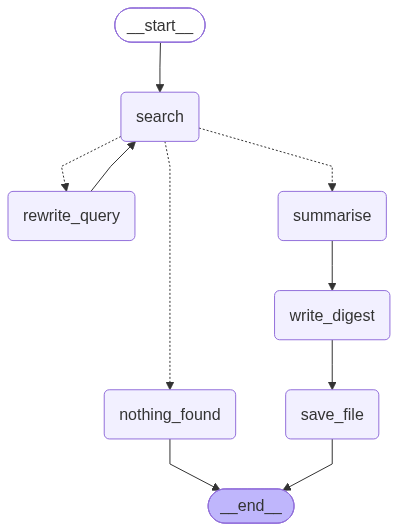

In [10]:
def rewrite_query(state: DigestState) -> dict:                # LLM, the only judgment step
    new_query = model.invoke(
        f"An arXiv search for '{state['query']}' found nothing. The scientist's topic is "
        f"'{state['topic']}'. Reply with ONE broader search query of at most 4 words, "
        "and nothing else."
    ).text.strip().strip("\"'")
    print(f"  LLM rewrote the query -> {new_query!r}")
    return {"query": new_query}


def nothing_found(state: DigestState) -> dict:                # code
    return {"digest": f"No new papers found on '{state['topic']}' "
                      f"after {state['attempts']} searches."}


def after_search(state: DigestState) -> str:                  # code: the routing rule
    if state["n_found"] > 0:
        return "summarise"
    if state["attempts"] < 3:
        return "rewrite_query"
    return "nothing_found"


builder = StateGraph(DigestState)
for step in (search, rewrite_query, summarise, write_digest, save_file, nothing_found):
    builder.add_node(step)
builder.add_edge(START, "search")
builder.add_conditional_edges("search", after_search,
                              ["summarise", "rewrite_query", "nothing_found"])
builder.add_edge("rewrite_query", "search")      # the one loop
builder.add_edge("summarise", "write_digest")
builder.add_edge("write_digest", "save_file")
builder.add_edge("save_file", END)
builder.add_edge("nothing_found", END)

agentic_workflow = builder.compile()
draw(agentic_workflow)

In [11]:
with track("3) Agentic workflow", "narrow topic") as run:
    out = agentic_workflow.invoke({"topic": NARROW})
    run["papers"] = arxiv_ids(out["digest"])

display(Markdown(out["digest"]))

  search('graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning') -> 0 papers
  LLM rewrote the query -> 'perovskite tandem solar cells'
  search('perovskite tandem solar cells') -> 5 papers

✓ 3) Agentic workflow (narrow topic): 3 LLM calls, 6,846 tokens, 29.3 s


Subject: Lab Weekly Digest — GO Interlayers, Humidity Stability, Perovskite Tandems & ML

Hi all,

Closest relevant hits this week for our GO-interlayer / humidity-stability / perovskite-tandem / ML thread:

- **High-Throughput Imaging of Degradation-Inducing Microscopic Impurities in Perovskite Solar Cells** — http://arxiv.org/abs/2609.35510v1 — nano-FTIR plus high-res optical/scanning probe and photo-stress shows degradation starts at impurity–perovskite interfaces; ML-supported reflected-light microscopy enables rapid, non-invasive detection.
- **Divergent Solid-state Conversion Pathways in Evaporated All-perovskite Tandem Solar Cells** — http://arxiv.org/abs/2609.20326v1 — time-sliced ex situ analysis reveals different WBG/NBG conversion mechanisms, including FA-species penetration and Br/I redistribution before substantial perovskite formation.
- **Terahertz Time-Domain Spectroscopy as a Universal Defect Fingerprinting Tool for Organic Halide Perovskite Solar Cells** — http://arxiv.org/abs/2607.15538v1 — short review: THz-TDS (0.3–3.0 THz) fingerprints intrinsic phonons and grain-boundary molecular defects across four OHP compositions at room temperature.
- **Characterizing Fill Factor Limitations in Perovskite-Silicon Tandem Solar Cells** — http://arxiv.org/abs/2604.24098v1 — FF loss in perovskite-Si tandems is tied to series resistance, photoshunt from moderate charge-transport-layer mobility, and Si two-diode behavior; photoshunt can be hidden under bottom-cell over-illumination.
- **Understanding halide segregation in metal halide perovskites through defect thermodynamics** — http://arxiv.org/abs/2603.07829v1 — first-principles slab calculations show Br prefers surface sites, with stronger segregation tendency in MAPb(Br$_x$I$_{1-x}$)$_3$ than FA$_{0.8}$Cs$_{0.2}$Pb(Br$_x$I$_{1-x}$)$_3$; bulk–surface Br antisite formation-energy difference is a descriptor for halide segregation.

Best,  
[Your name]

In [12]:
# And on the normal topic it behaves exactly like the plain workflow: the loop never runs.
with track("3) Agentic workflow", "normal topic") as run:
    out = agentic_workflow.invoke({"topic": TOPIC})
    run["papers"] = arxiv_ids(out["digest"])

  search('machine learning interatomic potentials for catalysis') -> 5 papers

✓ 3) Agentic workflow (normal topic): 2 LLM calls, 5,310 tokens, 17.4 s


This is the shape of most useful research pipelines, and of the citation checker in the
slides' exercise: **fixed outer steps, with the LLM looping only where the path cannot be
planned ahead.**

---
## Step 4: Agent. **The LLM** decides.

No graph of steps this time. We give the model three tools and a goal, and it chooses which
tools to call, in what order, and when to stop:

* `search_arxiv`;
* `check_seen`: a tiny "database" of papers you have already read (we pretend you read two of
  the papers from Step 2 last week);
* `save_digest`: writes the final email to a file.

In [13]:
from langchain.agents import create_agent

SEEN = set(arxiv_ids(search_arxiv(TOPIC, max_results=5))[:2])  # "read last week"


def check_seen(links: list[str]) -> str:
    """Check which papers the scientist has already read.

    Args:
        links: arXiv links or ids of the papers you are considering.
    """
    ids = arxiv_ids(" ".join(links))
    seen = [i for i in ids if i in SEEN]
    new = [i for i in ids if i not in SEEN]
    return f"Already read: {seen or 'none'}. Not read yet: {new or 'none'}."


def save_digest(content: str) -> str:
    """Save the finished digest email so the scientist can read it.

    Args:
        content: The full digest in markdown, starting with a subject line.
    """
    Path("digest_agent.md").write_text(content, encoding="utf-8")
    return "Saved digest_agent.md"


AGENT_PROMPT = (
    "You prepare a weekly digest of new arXiv papers for a scientist. "
    "Use search_arxiv to find papers; if a search finds nothing, try broader terms. "
    "Use check_seen and leave out papers the scientist has already read. "
    "Report only what the tools returned, with links. "
    "When the digest is ready, save it with save_digest."
)

digest_agent = create_agent(
    model, tools=[search_arxiv, check_seen, save_digest], system_prompt=AGENT_PROMPT
)

with track("4) Agent", "normal topic") as run:
    result = digest_agent.invoke(
        {"messages": [HumanMessage(f"Prepare this week's digest on {TOPIC}.")]}
    )
    run["papers"] = arxiv_ids(Path("digest_agent.md").read_text() if Path("digest_agent.md").exists() else "")

show_trace(result)


✓ 4) Agent (normal topic): 4 LLM calls, 23,791 tokens, 9.9 s
You:         Prepare this week's digest on machine learning interatomic potentials for catalysis.
Thought:     I'll search for recent papers on this topic.
Action:      search_arxiv({'query': 'machine learning interatomic potentials catalysis', 'max_results': '10'})
Action:      search_arxiv({'query': 'machine learning potential catalyst surface reaction', 'max_results': '10'})
Observation: 10 papers
Observation: 10 papers
Thought:     I found a good set of candidates. Let me check which ones the scientist has already read.
Action:      check_seen({'links': "['http://arxiv.org/abs/2610.02013v1', [...]"})
Observation: Already read: ['2609.09293', '2609.11602']. Not read yet: ['2501.00575', '2509.17833', [...]
Action:      save_digest({'content': '# Weekly Digest: Machine Learning Interatomic [...]'})
Observation: Saved digest_agent.md
Answer:      Digest saved. Here's a summary of what I did: **Searches run:** Two queries — "

In [14]:
# The same agent on the topic that is too specific.
Path("digest_agent.md").unlink(missing_ok=True)
with track("4) Agent", "narrow topic") as run:
    result = digest_agent.invoke(
        {"messages": [HumanMessage(f"Prepare this week's digest on {NARROW}.")]}
    )
    run["papers"] = arxiv_ids(Path("digest_agent.md").read_text() if Path("digest_agent.md").exists() else "")

show_trace(result)


✓ 4) Agent (narrow topic): 10 LLM calls, 111,744 tokens, 40.8 s
You:         Prepare this week's digest on graphene oxide interlayer humidity stability perovskite tandem solar cell machine learning.
Thought:     I'll search for recent papers on these topics. Let me start with several parallel searches.
Action:      search_arxiv({'max_results': '5', 'query': 'graphene oxide interlayer humidity stability [...]'})
Action:      search_arxiv({'max_results': '5', 'query': 'perovskite tandem solar cell machine learning'})
Action:      search_arxiv({'max_results': '5', 'query': 'graphene oxide humidity stability'})
Action:      search_arxiv({'max_results': '5', 'query': 'perovskite tandem solar cell'})
Observation: 0 papers
Observation: 1 papers
Observation: 4 papers
Observation: 5 papers
Thought:     Let me try broader terms for the graphene oxide–perovskite connection and related areas.
Action:      search_arxiv({'max_results': '5', 'query': 'graphene oxide perovskite solar cell stability'}

Nobody wrote "check what was already read before saving" or "retry with broader terms" as
code. The model chose it, and it might choose differently next time. That flexibility is the
point of an agent, and also its cost.

### Optional: a human approves before anything is saved

The slides recommended human approval before hard-to-undo actions. In LangChain this is
**middleware**: it pauses the agent before `save_digest` runs, shows you the request, and
waits for your decision. A *checkpointer* remembers where the run paused.

In [15]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

careful_agent = create_agent(
    model,
    tools=[search_arxiv, check_seen, save_digest],
    system_prompt=AGENT_PROMPT,
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"save_digest": True})],
    checkpointer=InMemorySaver(),
)
config = {"configurable": {"thread_id": "digest-with-approval"}}

result = careful_agent.invoke(
    {"messages": [HumanMessage(f"Prepare this week's digest on {TOPIC}.")]}, config
)
while "__interrupt__" in result:                       # the agent paused for you
    request = result["__interrupt__"][0].value["action_requests"][0]
    print(f"The agent wants to run {request['name']} with:\n")
    print(textwrap.shorten(str(request["args"]), 800), "\n")
    if input("Approve? [y/n] ").strip().lower().startswith("y"):
        decision = {"type": "approve"}
    else:
        decision = {"type": "reject", "message": "Not approved. Do not save it."}
    result = careful_agent.invoke(Command(resume={"decisions": [decision]}), config)

print(result["messages"][-1].text)

The agent wants to run save_digest with:

{'content': "# Weekly Digest: Machine Learning Interatomic Potentials for Catalysis\n\nHere are this week's new arXiv papers on MLIPs for catalysis (papers you've already read are excluded).\n\n---\n\n## 1. BranchIP: Learning Adaptive Equivariant Computation for Interatomic Potentials\n**Authors:** Laura Zichi, Gil Harari, Chuin Wei Tan et al.\n**Link:** http://arxiv.org/abs/2610.02013v1\n\nEquivariant MLIPs have revolutionized atomistic modeling, but accurate treatment of complex materials and molecular systems demands expensive models, limiting simulation length- and time-scales, with tensor products a key computational bottleneck. The recent emergence of foundation-scale MLIPs further exacerbates this challenge. The authors present BranchIP, a single-model framework for learned [...] 

Approve? [y/n] y
The digest is ready and saved. Here's a summary of what I did:

**Searches run:** Two arXiv searches — "machine learning interatomic potentia

---
## Step 5: Compare

Every tracked run went into `RUNS`. Same task, four levels, two topics:

In [16]:
WHO_DECIDES = {"1) LLM call": "You", "2) LLM workflow": "Your code",
               "3) Agentic workflow": "Code + LLM in one step", "4) Agent": "The LLM"}

table = pd.DataFrame(RUNS)
table.insert(1, "who decides", table["level"].map(WHO_DECIDES))
table["n_papers"] = table["papers"].map(len)
formatted_table = table.drop(columns="papers").sort_values(["topic", "level"], ignore_index=True)

# Left-justify the first column ('level') using Pandas styling
formatted_table.style.set_properties(subset=["level"], **{'text-align': 'left'})

,level,who decides,topic,llm_calls,tokens,seconds,n_papers
0,2) LLM workflow,Your code,narrow topic,2,1533,8.900000,0
1,3) Agentic workflow,Code + LLM in one step,narrow topic,3,6846,29.300000,5
2,4) Agent,The LLM,narrow topic,10,111744,40.800000,25
3,1) LLM call,You,normal topic,1,708,2.300000,1
4,2) LLM workflow,Your code,normal topic,2,5575,16.700000,5
5,3) Agentic workflow,Code + LLM in one step,normal topic,2,5310,17.400000,5
6,4) Agent,The LLM,normal topic,4,23791,9.900000,17


Now **reproducibility**. Run the workflow and the agent once more on the normal topic, and
check whether they report the same papers as the first time.

In [18]:
first = {row["level"]: set(row["papers"]) for row in RUNS if row["topic"] == "normal topic"}

with track("2) LLM workflow", "normal topic, re-run") as run:
    run["papers"] = arxiv_ids(workflow.invoke({"topic": TOPIC})["digest"])
print("Workflow: same papers as the first run?", set(run["papers"]) == first["2) LLM workflow"])

Path("digest_agent.md").unlink(missing_ok=True)
with track("4) Agent", "normal topic, re-run") as run:
    digest_agent.invoke({"messages": [HumanMessage(f"Prepare this week's digest on {TOPIC}.")]})
    run["papers"] = arxiv_ids(Path("digest_agent.md").read_text() if Path("digest_agent.md").exists() else "")
print("Agent:    same papers as the first run?", set(run["papers"]) == first["4) Agent"])

  search('machine learning interatomic potentials for catalysis') -> 5 papers

✓ 2) LLM workflow (normal topic, re-run): 2 LLM calls, 4,762 tokens, 16.3 s
Workflow: same papers as the first run? True

✓ 4) Agent (normal topic, re-run): 4 LLM calls, 23,399 tokens, 9.0 s
Agent:    same papers as the first run? False


### What to notice

* **Cost grows with autonomy.** Count the LLM calls and tokens per level. The agent resends
  its whole context at every step.
* **Only the levels with an LLM decision coped with the narrow topic.** The plain workflow
  wrote an empty (or invented) digest.
* **Reproducibility falls with autonomy.** The workflow's search is fixed code, so its papers
  only change when arXiv does. The agent picks its own queries.
* The agentic workflow got the robustness of the agent on the narrow topic, at the cost and
  predictability of the workflow on the normal one.

That is the decision tree from the slides:

> Can one prompt do it? → **LLM call**. Are all the steps known in advance? → **LLM
> workflow**. Does only part of it need run-time judgment? → **agentic workflow**. Otherwise →
> **agent**. *Start with the simplest option. Add autonomy only when it pays off.*

### What about agents that run other agents?

An agent's tool can itself be another agent: a lead agent decides at run time which
specialist agents to call, gives them sub-tasks, and combines their answers. That is a
**multi-agent system**, the topic of **Tutorial 4**.

---
## Your turn (take-home)

Pick a task from your own work, or the citation checker from the slides ("is every reference
real, and does it support the sentence that cites it?"). Answer in the cell below, then try
building it at the level you chose, starting from the closest graph or agent above.

| | Your answer |
|---|---|
| Trigger / input | |
| Steps | |
| Tools | |
| Where the LLM decides | |
| How you check it | |
| LLM call, workflow, agentic workflow or agent? Why? | |

---
*AgentForge Workshop, Tutorial 1B. Questions, fixes and better examples are welcome:
<https://github.com/AgentForgeWorkshop/Tutorials>*